In [1]:
# ==========================================
# 1. Data Handling
# ==========================================
import numpy as np
import pandas as pd

# ==========================================
# 2. Data Visualization
# ==========================================
import matplotlib.pyplot as plt

# ==========================================
# 3. Data Splitting
# ==========================================
from sklearn.model_selection import train_test_split, StratifiedKFold

# ==========================================
# 4. Data Preprocessing
# ==========================================
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# ==========================================
# 5. Feature Selection
# ==========================================
from sklearn.feature_selection import (
    mutual_info_classif,
    RFECV
)
from sklearn.inspection import permutation_importance

# ==========================================
# 6. Machine Learning Models
# ==========================================
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

# ==========================================
# 7. Model Evaluation
# ==========================================
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    make_scorer
)

# ==========================================
# 8. Notebook Display
# ==========================================
from IPython.display import display

In [2]:
df = pd.read_csv("D:\\GitHub\\Python\\Customer_Churn\\Telco-Customer-Churn.csv")

In [3]:
##Dataset dimensions
df.shape

(7043, 21)

In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.info 

<bound method DataFrame.info of       customerID  gender  SeniorCitizen Partner Dependents  tenure  \
0     7590-VHVEG  Female              0     Yes         No       1   
1     5575-GNVDE    Male              0      No         No      34   
2     3668-QPYBK    Male              0      No         No       2   
3     7795-CFOCW    Male              0      No         No      45   
4     9237-HQITU  Female              0      No         No       2   
...          ...     ...            ...     ...        ...     ...   
7038  6840-RESVB    Male              0     Yes        Yes      24   
7039  2234-XADUH  Female              0     Yes        Yes      72   
7040  4801-JZAZL  Female              0     Yes        Yes      11   
7041  8361-LTMKD    Male              1     Yes         No       4   
7042  3186-AJIEK    Male              0      No         No      66   

     PhoneService     MultipleLines InternetService OnlineSecurity  ...  \
0              No  No phone service             DSL 

In [6]:
##Summary of numerical columns
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [7]:
##Summary of categorical columns
df.describe(include="object")

C:\Users\jsing\AppData\Local\Temp\ipykernel_7864\2425004135.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,TotalCharges,Churn
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043
unique,7043,2,2,2,2,3,3,3,3,3,3,3,3,3,2,4,6531,2
top,7590-VHVEG,Male,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,20.2,No
freq,1,3555,3641,4933,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,11,5174


In [8]:
df["Churn"].nunique()

2

In [9]:
df["Churn"].unique()

<StringArray>
['No', 'Yes']
Length: 2, dtype: str

In [10]:
##Count customers by churn status
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [11]:
round(df["Churn"].value_counts(normalize=True)*100,2)

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

In [12]:
df.isnull().sum()
#df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [13]:
df.duplicated().sum()               
#df[df.duplicated(keep=False)]
#df = df.drop_duplicates()
#df.duplicated().sum()

np.int64(0)

In [14]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [15]:
df["TotalCharges"].dtype

<StringDtype(storage='python', na_value=nan)>

In [16]:
#------STEP 3: EXPLORATORY DATA ANALYSIS (EDA) ----------------------------------------------------

In [17]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [18]:
round(df["Churn"].value_counts(normalize=True)*100,2)

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

In [19]:
(df["Churn"]=="Yes").mean()*100

np.float64(26.536987079369588)

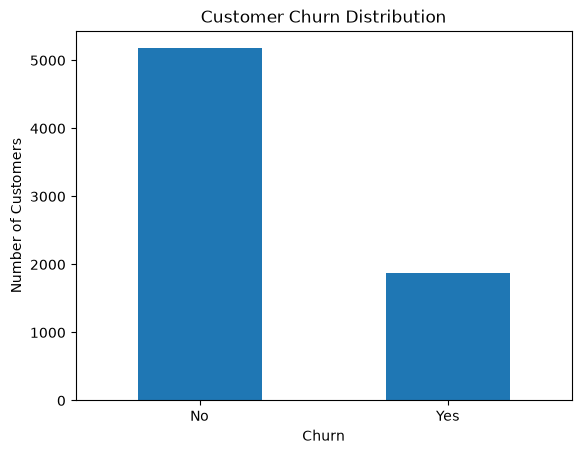

In [20]:
df["Churn"].value_counts().plot(kind="bar")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.xticks(rotation= 0)
plt.show()

In [21]:
pd.crosstab(df["Contract"],df["Churn"])

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


In [22]:
pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize = "index"
) *100

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


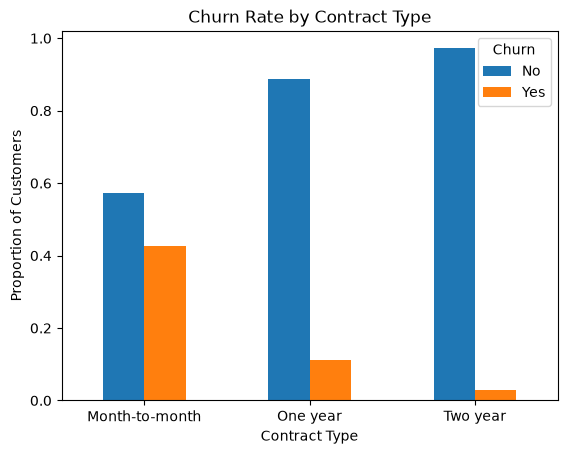

In [23]:
ax = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize = "index"
).plot(kind="bar")

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Proportion of Customers")
plt.xticks(rotation=0)
plt.show()

In [24]:
df.groupby("Churn")["tenure"].mean()

Churn
No     37.569965
Yes    17.979133
Name: tenure, dtype: float64

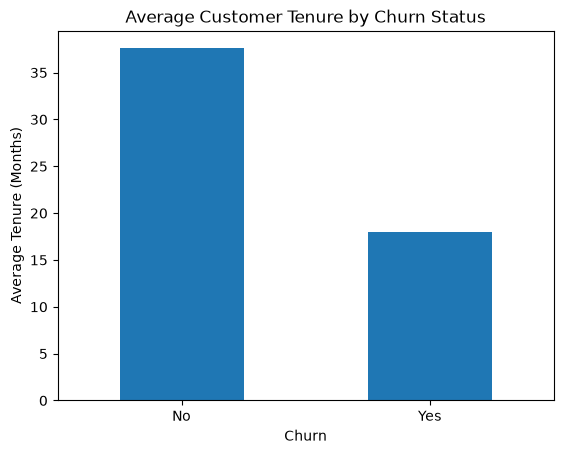

In [25]:
df.groupby("Churn")["tenure"].mean().plot(kind="bar")

plt.title("Average Customer Tenure by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Average Tenure (Months)")
plt.xticks(rotation=0)
plt.show()

In [26]:
df.groupby("Churn")["MonthlyCharges"].mean()

Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64

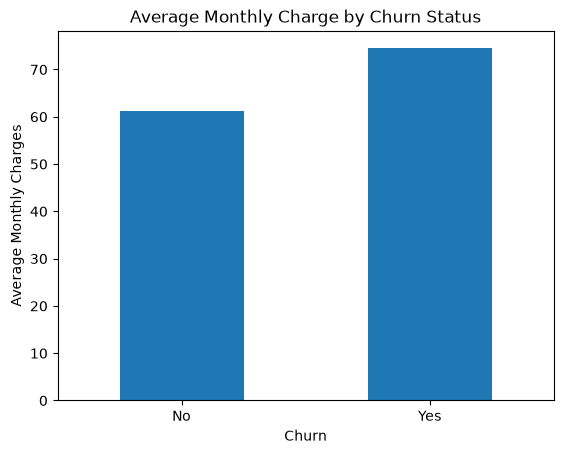

In [27]:
df.groupby("Churn")["MonthlyCharges"].mean().plot(kind="bar")

plt.title("Average Monthly Charge by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Average Monthly Charges")
plt.xticks(rotation=0)
plt.show()

In [28]:
#Calculate the difference
charges = df.groupby("Churn")["MonthlyCharges"].mean()

charges["Yes"]-charges["No"]

##Result shows that customers who churned paid an average of 13.176 more per month than customers who stayed.
##This is another useful finding for this project. Higher monthly charges may be associated with churn.

np.float64(13.176208567842295)

In [29]:
#Calculate churn percentages
pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) *100

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


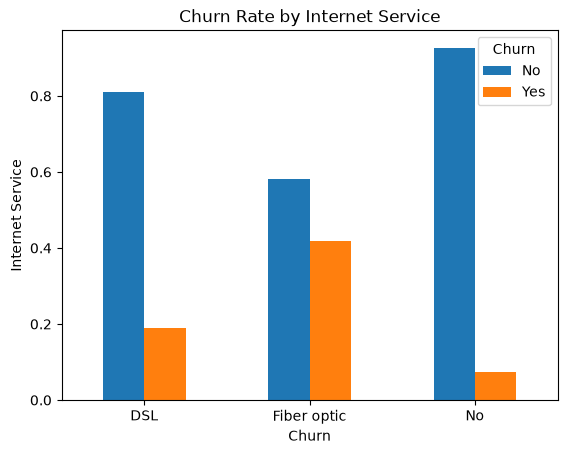

In [30]:
pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
).plot(kind="bar")

plt.title("Churn Rate by Internet Service")
plt.xlabel("Churn")
plt.ylabel("Internet Service")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.show()

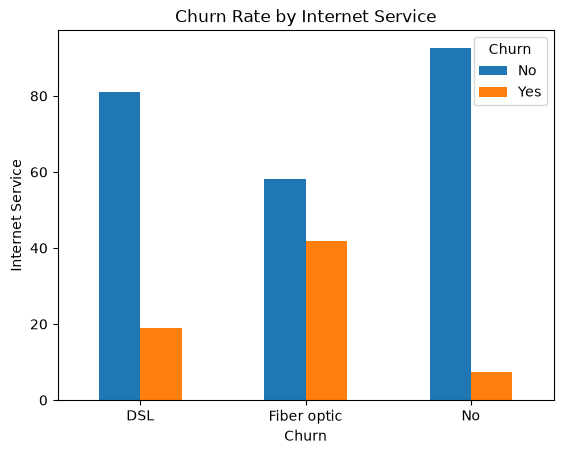

In [31]:
ax=(pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
)*100).plot(kind="bar")

plt.title("Churn Rate by Internet Service")
plt.xlabel("Churn")
plt.ylabel("Internet Service")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.show()

In [32]:
pd.crosstab(
    df["TechSupport"],
    df["Churn"],
    normalize="index"
)*100

Churn,No,Yes
TechSupport,,
No,58.364526,41.635474
No internet service,92.595020,7.404980
Yes,84.833659,15.166341


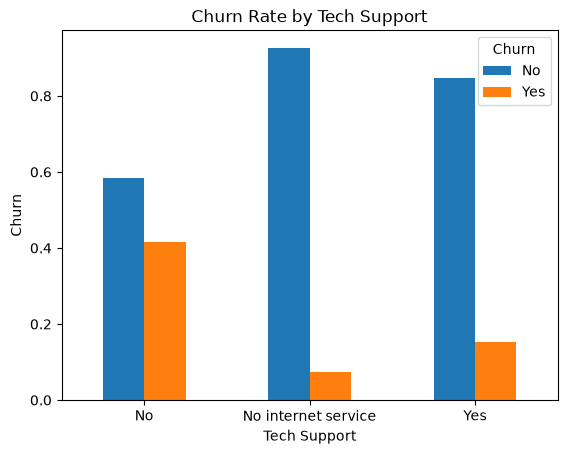

In [33]:
pd.crosstab(
    df["TechSupport"],
    df["Churn"],
    normalize="index"
).plot(kind="bar")

plt.title("Churn Rate by Tech Support")
plt.xlabel("Tech Support")
plt.ylabel("Churn")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.show()

In [34]:
pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
)*100

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


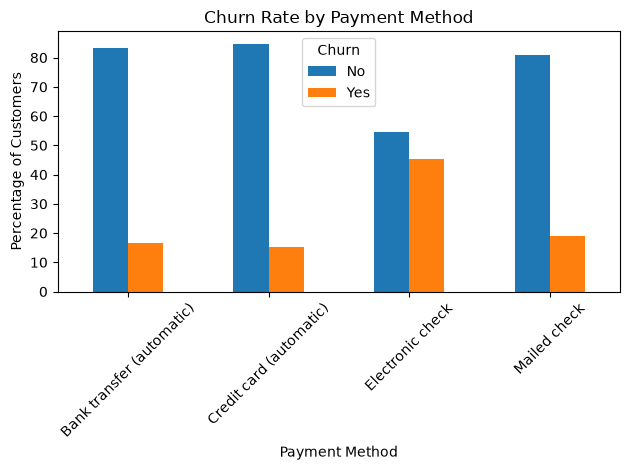

In [35]:
ax=(pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
)*100).plot(kind="bar")

plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=45, ha="center")
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

In [36]:
#Factor	             Finding
#Contract	         Month-to-month customers churn more
#Tenure	             Churned customers have lower average tenure
#Monthly charges	 Churned customers pay more on average
#Internet service	 Fiber optic customers have the highest churn
#Tech support	     Customers without Tech Support churn more
#Payment method	     Electronic check customers have the highest churn

#These findings will later help me explain the business problem and prepare the data for machine learning.

In [37]:
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[0, 12, 24, 36, 48, 60, 72],
    labels =["0-12 Months", "13-24 Months", "25-36 Months", "37-48 Months", "49-60 Months", "61-72 Months"],
    include_lowest = True
)

In [38]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TenureGroup
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0-12 Months
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,No,One year,No,Mailed check,56.95,1889.5,No,25-36 Months
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,0-12 Months
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,37-48 Months
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,0-12 Months


In [39]:
pd.crosstab(
    df["TenureGroup"],
    df["Churn"],
    normalize="index"
)*100

Churn,No,Yes
TenureGroup,,
0-12 Months,52.561757,47.438243
13-24 Months,71.289062,28.710938
25-36 Months,78.365385,21.634615
37-48 Months,80.971129,19.028871
49-60 Months,85.576923,14.423077
61-72 Months,93.390192,6.609808


In [40]:
#Compare churn by Senior Citizen status
pd.crosstab(
    df["SeniorCitizen"],
    df["Churn"],
    normalize = "index"
)*100

Churn,No,Yes
SeniorCitizen,,
0,76.393832,23.606168
1,58.318739,41.681261


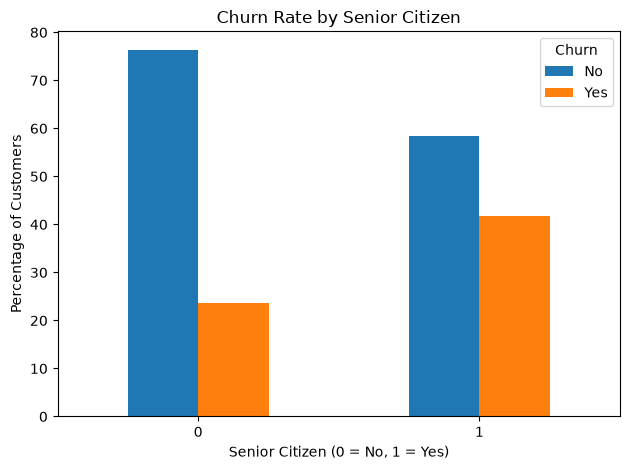

In [41]:
ax=(
    pd.crosstab(
    df["SeniorCitizen"],
    df["Churn"],
    normalize = "index"
)*100
).plot(kind="bar")

plt.title("Churn Rate by Senior Citizen")
plt.xlabel("Senior Citizen (0 = No, 1 = Yes)")
plt.ylabel("Percentage of Customers")
plt.legend(title="Churn")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [42]:
pd.crosstab(
    df["Dependents"],
    df["Churn"],
    normalize="index"
)*100

Churn,No,Yes
Dependents,,
No,68.720860,31.279140
Yes,84.549763,15.450237


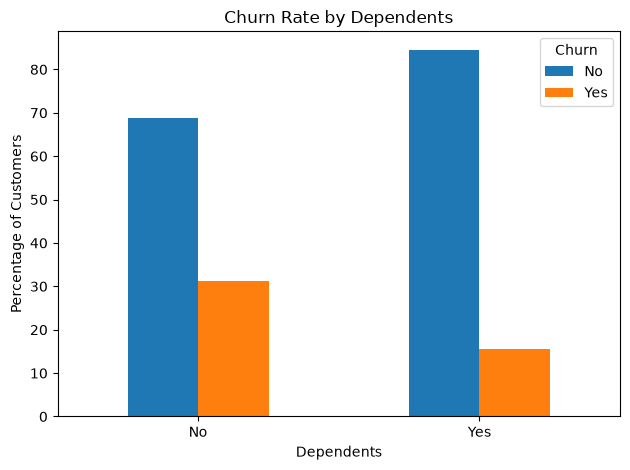

In [43]:
ax=(
    pd.crosstab(
    df["Dependents"],
    df["Churn"],
    normalize="index"
)*100
).plot(kind="bar")

plt.title("Churn Rate by Dependents")
plt.xlabel("Dependents")
plt.ylabel("Percentage of Customers")
plt.legend(title="Churn")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [44]:
pd.crosstab(
    df["Partner"],
    df["Churn"],
    normalize="index"
)*100

Churn,No,Yes
Partner,,
No,67.042021,32.957979
Yes,80.335097,19.664903


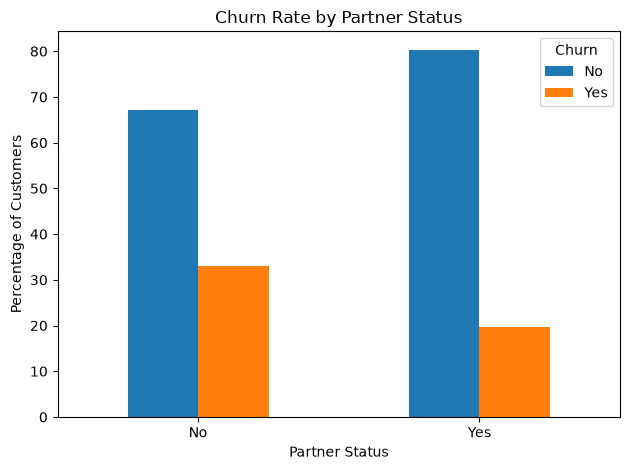

In [45]:
ax= (
    pd.crosstab(
    df["Partner"],
    df["Churn"],
    normalize="index"
)*100
).plot(kind="bar")

plt.title("Churn Rate by Partner Status")
plt.xlabel("Partner Status")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.legend(title="Churn")
plt.show()

In [46]:
pd.crosstab(
    df["gender"],
    df["Churn"],
    normalize="index"
)*100

## Doesn't look like have much affect

Churn,No,Yes
gender,,
Female,73.079128,26.920872
Male,73.839662,26.160338


In [47]:
#Overall churn rate
print("Overall Churn Rate:")
print(round((df["Churn"] == "Yes").mean()*100,2),"%")

# Churn rate by contract
print("\nChurn Rate by Contract:")
print(
    df.groupby("Contract", observed=True)["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
      .round(2)
)

# Churn rate by tech support
print("\nChurn Rate by Tech Support:")
print(
    df.groupby("TechSupport", observed=True)["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
      .round(2)
)

# Churn rate by payment method
print("\nChurn Rate by Payment Method:")
print(
    df.groupby("PaymentMethod", observed=True)["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
      .round(2)
)

Overall Churn Rate:
26.54 %

Churn Rate by Contract:
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64

Churn Rate by Tech Support:
TechSupport
No                     41.64
No internet service     7.40
Yes                    15.17
Name: Churn, dtype: float64

Churn Rate by Payment Method:
PaymentMethod
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Electronic check             45.29
Mailed check                 19.11
Name: Churn, dtype: float64


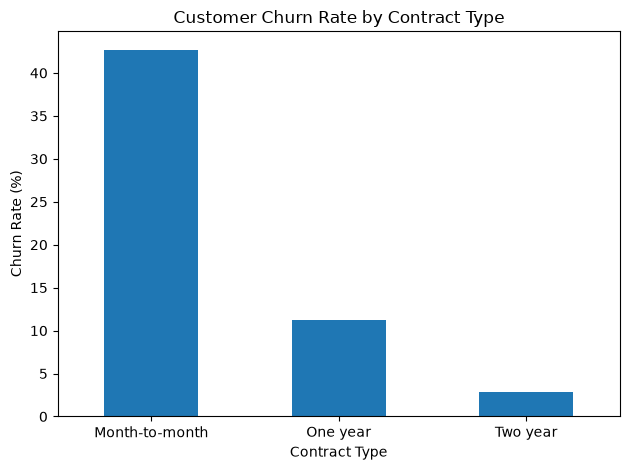

In [48]:
contract_churn = (
    df.groupby("Contract")["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
      .sort_values(ascending=False)
)

contract_churn.plot(kind="bar")

plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [49]:
#Check data types and missing values
df.dtypes

customerID               str
gender                   str
SeniorCitizen          int64
Partner                  str
Dependents               str
tenure                 int64
PhoneService             str
MultipleLines            str
InternetService          str
OnlineSecurity           str
OnlineBackup             str
DeviceProtection         str
TechSupport              str
StreamingTV              str
StreamingMovies          str
Contract                 str
PaperlessBilling         str
PaymentMethod            str
MonthlyCharges       float64
TotalCharges             str
Churn                    str
TenureGroup         category
dtype: object

In [50]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
TenureGroup         0
dtype: int64

In [51]:
df.duplicated().sum() 

np.int64(0)

In [52]:
# Check blank strings in TotalCharges
(df["TotalCharges"].astype(str).str.strip() == "").sum()

np.int64(11)

In [53]:
df["TotalCharges"] = df["TotalCharges"].replace(r"^\s*$", np.nan, regex=True)

In [54]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

In [55]:
print("Data type:", df["TotalCharges"].dtype)
print("Missing values:", df["TotalCharges"].isna().sum())

Data type: float64
Missing values: 11


In [56]:
df[df["TotalCharges"].isna()]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TenureGroup
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No,0-12 Months
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No,0-12 Months
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No,0-12 Months
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No,0-12 Months
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No,0-12 Months
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No,0-12 Months
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No,0-12 Months
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No,0-12 Months
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No,0-12 Months
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No,0-12 Months


In [57]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [58]:
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isna().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Dataset shape: (7043, 22)

Missing values:
0

Duplicate rows:
0


In [59]:
df.dtypes

customerID               str
gender                   str
SeniorCitizen          int64
Partner                  str
Dependents               str
tenure                 int64
PhoneService             str
MultipleLines            str
InternetService          str
OnlineSecurity           str
OnlineBackup             str
DeviceProtection         str
TechSupport              str
StreamingTV              str
StreamingMovies          str
Contract                 str
PaperlessBilling         str
PaymentMethod            str
MonthlyCharges       float64
TotalCharges         float64
Churn                    str
TenureGroup         category
dtype: object

In [60]:
print("Missing values per column:")
print(df.isna().sum()[df.isna().sum() > 0])

print("\nChurn counts:")
print(df["Churn"].value_counts())

print("\nChurn percentage:")
print(
    df["Churn"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Missing values per column:
Series([], dtype: int64)

Churn counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentage:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [61]:
# Target: what we want to predict
y = df["Churn"]

# Predictors: variables used to make predictions
X = df.drop(
    columns=["Churn", "customerID", "TenureGroup"]
)

print("Predictor shape:", X.shape)
print("Target shape:", y.shape)

print("\nCategorical predictors:")
print(X.select_dtypes(include=["str", "object", "category"]).columns.tolist())

print("\nNumerical predictors:")
print(X.select_dtypes(include="number").columns.tolist())

Predictor shape: (7043, 19)
Target shape: (7043,)

Categorical predictors:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numerical predictors:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


In [62]:
# Separate target and predictor features
y = df["Churn"]
X = df.drop(columns=["Churn", "customerID", "TenureGroup"], errors="ignore")

# First split: 70% temporary training data, 15% test data
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=42,
    stratify=y
)

# Second split: divide remaining 85% into 70% training and 15% validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.15 / 0.85,
    random_state=42,
    stratify=y_train_val
)

# Display dataset sizes
print("Training set:", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Test set:", X_test.shape, y_test.shape)

print("\nChurn distribution (%):")
print("Training:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nValidation:")
print((y_val.value_counts(normalize=True) * 100).round(2))

print("\nTest:")
print((y_test.value_counts(normalize=True) * 100).round(2))

Training set: (4929, 19) (4929,)
Validation set: (1057, 19) (1057,)
Test set: (1057, 19) (1057,)

Churn distribution (%):
Training:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

Validation:
Churn
No     73.42
Yes    26.58
Name: proportion, dtype: float64

Test:
Churn
No     73.51
Yes    26.49
Name: proportion, dtype: float64


In [63]:
# Identify numerical and categorical columns
num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(
    include=["object", "category", "str", "bool"]
).columns.tolist()

# Preprocessing for numerical variables
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing for categorical variables
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

# Fit preprocessing on training data only
X_train_encoded = preprocessor.fit_transform(X_train)

# Get names of the encoded features
feature_names = preprocessor.get_feature_names_out()

# Store encoded training data as a DataFrame
X_train_encoded = pd.DataFrame(
    X_train_encoded,
    columns=feature_names,
    index=X_train.index
)

# Mark categorical encoded columns for Mutual Information
discrete_mask = np.array([
    name.startswith("cat__") for name in feature_names
])

print("Original numerical variables:", len(num_cols))
print("Original categorical variables:", len(cat_cols))
print("Total encoded features:", len(feature_names))
print("Encoded training shape:", X_train_encoded.shape)

Original numerical variables: 4
Original categorical variables: 15
Total encoded features: 45
Encoded training shape: (4929, 45)


In [64]:
##BEFORE RUNNING "LOGISTIC REGRESSION" SELECTING FEATURES WITH DIFFERENT TECHNIQUES

In [65]:
#Method 1: All variables

In [66]:
# Keep every encoded feature
features_all = X_train_encoded.columns.tolist()

print("Total selected features:", len(features_all))
print(features_all)

Total selected features: 45
['num__SeniorCitizen', 'num__tenure', 'num__MonthlyCharges', 'num__TotalCharges', 'cat__gender_Female', 'cat__gender_Male', 'cat__Partner_No', 'cat__Partner_Yes', 'cat__Dependents_No', 'cat__Dependents_Yes', 'cat__PhoneService_No', 'cat__PhoneService_Yes', 'cat__MultipleLines_No', 'cat__MultipleLines_No phone service', 'cat__MultipleLines_Yes', 'cat__InternetService_DSL', 'cat__InternetService_Fiber optic', 'cat__InternetService_No', 'cat__OnlineSecurity_No', 'cat__OnlineSecurity_No internet service', 'cat__OnlineSecurity_Yes', 'cat__OnlineBackup_No', 'cat__OnlineBackup_No internet service', 'cat__OnlineBackup_Yes', 'cat__DeviceProtection_No', 'cat__DeviceProtection_No internet service', 'cat__DeviceProtection_Yes', 'cat__TechSupport_No', 'cat__TechSupport_No internet service', 'cat__TechSupport_Yes', 'cat__StreamingTV_No', 'cat__StreamingTV_No internet service', 'cat__StreamingTV_Yes', 'cat__StreamingMovies_No', 'cat__StreamingMovies_No internet service', '

In [67]:
#Method 2: Mutual Information

In [68]:
mi_scores = mutual_info_classif(
    X_train_encoded,
    y_train,
    discrete_features=discrete_mask,
    random_state=42
)

mi_results = pd.DataFrame({
    "Feature": X_train_encoded.columns,
    "MI_Score": mi_scores
}).sort_values("MI_Score", ascending=False)

# Select top 15 features
top_n = min(15, len(mi_results))
features_mi = mi_results.head(top_n)["Feature"].tolist()

print("Top features by Mutual Information:")
display(mi_results.head(20))

print("\nSelected features:", len(features_mi))
print(features_mi)

Top features by Mutual Information:


,Feature,MI_Score
36,cat__Contract_Month-to-month,0.096493
1,num__tenure,0.076718
38,cat__Contract_Two year,0.062525
27,cat__TechSupport_No,0.060935
18,cat__OnlineSecurity_No,0.060718
2,num__MonthlyCharges,0.050657
16,cat__InternetService_Fiber optic,0.049201
43,cat__PaymentMethod_Electronic check,0.045925
3,num__TotalCharges,0.039295
21,cat__OnlineBackup_No,0.036839



Selected features: 15
['cat__Contract_Month-to-month', 'num__tenure', 'cat__Contract_Two year', 'cat__TechSupport_No', 'cat__OnlineSecurity_No', 'num__MonthlyCharges', 'cat__InternetService_Fiber optic', 'cat__PaymentMethod_Electronic check', 'num__TotalCharges', 'cat__OnlineBackup_No', 'cat__OnlineBackup_No internet service', 'cat__DeviceProtection_No internet service', 'cat__TechSupport_No internet service', 'cat__StreamingTV_No internet service', 'cat__OnlineSecurity_No internet service']


In [69]:
#Method 3: L1 Regularization

In [70]:
l1_model = LogisticRegression(
    solver="liblinear",
    l1_ratio=1,
    C=0.1,
    class_weight="balanced",
    max_iter=5000,
    random_state=42
)

l1_model.fit(X_train_encoded, y_train)

# Extract coefficients
l1_coefficients = pd.DataFrame({
    "Feature": X_train_encoded.columns,
    "Coefficient": l1_model.coef_[0]
})

l1_coefficients["Abs_Coefficient"] = (
    l1_coefficients["Coefficient"].abs()
)

# Select features with non-zero coefficients
features_l1 = l1_coefficients.loc[
    l1_coefficients["Abs_Coefficient"] > 1e-6,
    "Feature"
].tolist()

l1_coefficients = l1_coefficients.sort_values(
    "Abs_Coefficient",
    ascending=False
)

print("Selected features:", len(features_l1))
display(l1_coefficients.head(20))

print("\nL1-selected features:")
print(features_l1)

Selected features: 20


,Feature,Coefficient,Abs_Coefficient
1,num__tenure,-0.871024,0.871024
36,cat__Contract_Month-to-month,0.760543,0.760543
2,num__MonthlyCharges,0.744209,0.744209
11,cat__PhoneService_Yes,-0.731572,0.731572
38,cat__Contract_Two year,-0.606941,0.606941
29,cat__TechSupport_Yes,-0.455795,0.455795
39,cat__PaperlessBilling_No,-0.340912,0.340912
43,cat__PaymentMethod_Electronic check,0.332696,0.332696
20,cat__OnlineSecurity_Yes,-0.240452,0.240452
9,cat__Dependents_Yes,-0.185368,0.185368



L1-selected features:
['num__SeniorCitizen', 'num__tenure', 'num__MonthlyCharges', 'num__TotalCharges', 'cat__Dependents_Yes', 'cat__PhoneService_Yes', 'cat__MultipleLines_No', 'cat__InternetService_DSL', 'cat__InternetService_Fiber optic', 'cat__OnlineSecurity_No', 'cat__OnlineSecurity_Yes', 'cat__OnlineBackup_No', 'cat__OnlineBackup_Yes', 'cat__DeviceProtection_Yes', 'cat__TechSupport_No', 'cat__TechSupport_Yes', 'cat__Contract_Month-to-month', 'cat__Contract_Two year', 'cat__PaperlessBilling_No', 'cat__PaymentMethod_Electronic check']


In [71]:
#Method 4: RFECV

In [72]:
rfecv_estimator = LogisticRegression(
    solver="liblinear",
    l1_ratio=0,
    class_weight="balanced",
    max_iter=5000,
    random_state=42
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Calculate F1 specifically for customers who churn ("Yes")
f1_yes_scorer = make_scorer(
    f1_score,
    pos_label="Yes"
)

rfecv = RFECV(
    estimator=rfecv_estimator,
    step=1,
    min_features_to_select=5,
    cv=cv,
    scoring=f1_yes_scorer,
    n_jobs=-1
)

rfecv.fit(X_train_encoded, y_train)

# Extract selected features
features_rfecv = X_train_encoded.columns[
    rfecv.support_
].tolist()

print("Optimal number of features:", rfecv.n_features_)
print("Selected features:")
print(features_rfecv)

# Display RFECV cross-validation scores
rfecv_results = pd.DataFrame({
    "Number_of_Features": rfecv.cv_results_["n_features"],
    "Mean_CV_F1_Yes": rfecv.cv_results_["mean_test_score"]
})

display(rfecv_results)

Optimal number of features: 36
Selected features:
['num__tenure', 'num__MonthlyCharges', 'num__TotalCharges', 'cat__gender_Male', 'cat__Partner_No', 'cat__Partner_Yes', 'cat__Dependents_Yes', 'cat__PhoneService_Yes', 'cat__MultipleLines_No', 'cat__InternetService_DSL', 'cat__InternetService_Fiber optic', 'cat__InternetService_No', 'cat__OnlineSecurity_No', 'cat__OnlineSecurity_No internet service', 'cat__OnlineSecurity_Yes', 'cat__OnlineBackup_No', 'cat__OnlineBackup_No internet service', 'cat__DeviceProtection_No internet service', 'cat__TechSupport_No', 'cat__TechSupport_No internet service', 'cat__TechSupport_Yes', 'cat__StreamingTV_No', 'cat__StreamingTV_No internet service', 'cat__StreamingTV_Yes', 'cat__StreamingMovies_No', 'cat__StreamingMovies_No internet service', 'cat__StreamingMovies_Yes', 'cat__Contract_Month-to-month', 'cat__Contract_One year', 'cat__Contract_Two year', 'cat__PaperlessBilling_No', 'cat__PaperlessBilling_Yes', 'cat__PaymentMethod_Bank transfer (automatic)',

,Number_of_Features,Mean_CV_F1_Yes
0,5,0.616010
1,6,0.613461
2,7,0.617412
3,8,0.623535
4,9,0.621645
5,10,0.621605
6,11,0.622743
7,12,0.625947
8,13,0.625114
9,14,0.626743


In [73]:
#----------------------LOGISTIC REGRESSION--------------------------------------------

In [74]:
##LOGISTIC REGRESSION WITH ALL VARIABLES

In [75]:
# Select all features
X_train_all = X_train_encoded[features_all]

# Create the Logistic Regression model
lr_all = LogisticRegression(
    solver="liblinear",
    l1_ratio=0,
    class_weight="balanced",
    max_iter=5000,
    random_state=42
)

# Train the model
lr_all.fit(X_train_all, y_train)

print("Model trained successfully!")
print("Number of features used:", len(features_all))
print("Number of training records:", X_train_all.shape[0])

Model trained successfully!
Number of features used: 45
Number of training records: 4929


In [76]:
# Transform validation data using the existing fitted preprocessor
X_val_encoded = pd.DataFrame(
    preprocessor.transform(X_val),
    columns=feature_names,
    index=X_val.index
)

# Select all 45 features
X_val_all = X_val_encoded[features_all]

# Predict customer churn
y_val_pred_all = lr_all.predict(X_val_all)

# Evaluate the model
print("Accuracy:", round(accuracy_score(y_val, y_val_pred_all), 4))
print("Precision (Churn = Yes):",
      round(precision_score(y_val, y_val_pred_all, pos_label="Yes", zero_division=0), 4))
print("Recall (Churn = Yes):",
      round(recall_score(y_val, y_val_pred_all, pos_label="Yes", zero_division=0), 4))
print("F1-score (Churn = Yes):",
      round(f1_score(y_val, y_val_pred_all, pos_label="Yes", zero_division=0), 4))

# Confusion matrix
cm = confusion_matrix(y_val, y_val_pred_all, labels=["No", "Yes"])
display(pd.DataFrame(
    cm,
    index=["Actual No", "Actual Yes"],
    columns=["Predicted No", "Predicted Yes"]
))

# Detailed classification report
print(classification_report(y_val, y_val_pred_all, zero_division=0))

Accuracy: 0.7427
Precision (Churn = Yes): 0.5106
Recall (Churn = Yes): 0.7687
F1-score (Churn = Yes): 0.6136


,Predicted No,Predicted Yes
Actual No,569,207
Actual Yes,65,216


              precision    recall  f1-score   support

          No       0.90      0.73      0.81       776
         Yes       0.51      0.77      0.61       281

    accuracy                           0.74      1057
   macro avg       0.70      0.75      0.71      1057
weighted avg       0.79      0.74      0.76      1057



In [77]:
##LOGISTIC REGRESSION WITH MI

In [78]:
# Select MI features
X_train_mi = X_train_encoded[features_mi]
X_val_mi = X_val_encoded[features_mi]

# Create and train the model
lr_mi = LogisticRegression(
    solver="liblinear",
    l1_ratio=0,
    class_weight="balanced",
    max_iter=5000,
    random_state=42
)

lr_mi.fit(X_train_mi, y_train)

# Predict on validation data
y_val_pred_mi = lr_mi.predict(X_val_mi)

# Evaluate
mi_result = {
    "Method": "Mutual Information",
    "Features": len(features_mi),
    "Accuracy": accuracy_score(y_val, y_val_pred_mi),
    "Precision_Yes": precision_score(
        y_val, y_val_pred_mi, pos_label="Yes", zero_division=0
    ),
    "Recall_Yes": recall_score(
        y_val, y_val_pred_mi, pos_label="Yes", zero_division=0
    ),
    "F1_Yes": f1_score(
        y_val, y_val_pred_mi, pos_label="Yes", zero_division=0
    )
}

display(pd.DataFrame([mi_result]).round(4))

,Method,Features,Accuracy,Precision_Yes,Recall_Yes,F1_Yes
0,Mutual Information,15,0.7332,0.4989,0.7829,0.6094


In [79]:
##LOGISTIC REGRESSION WITH L1

In [80]:
# Select L1-selected features
X_train_l1 = X_train_encoded[features_l1]
X_val_l1 = X_val_encoded[features_l1]

# Create and train the model
lr_l1 = LogisticRegression(
    solver="liblinear",
    l1_ratio=0,
    class_weight="balanced",
    max_iter=5000,
    random_state=42
)

lr_l1.fit(X_train_l1, y_train)

# Predict on validation data
y_val_pred_l1 = lr_l1.predict(X_val_l1)

# Evaluate the model
l1_result = {
    "Method": "L1 Regularization",
    "Features": len(features_l1),
    "Accuracy": accuracy_score(y_val, y_val_pred_l1),
    "Precision_Yes": precision_score(
        y_val, y_val_pred_l1, pos_label="Yes", zero_division=0
    ),
    "Recall_Yes": recall_score(
        y_val, y_val_pred_l1, pos_label="Yes", zero_division=0
    ),
    "F1_Yes": f1_score(
        y_val, y_val_pred_l1, pos_label="Yes", zero_division=0
    )
}

display(pd.DataFrame([l1_result]).round(4))

,Method,Features,Accuracy,Precision_Yes,Recall_Yes,F1_Yes
0,L1 Regularization,20,0.7408,0.5082,0.7722,0.613


In [81]:
##LOGISTIC REGRESSION WITH RFECV

In [82]:
# Select RFECV-selected features
X_train_rfecv = X_train_encoded[features_rfecv]
X_val_rfecv = X_val_encoded[features_rfecv]

# Create and train the final model
lr_rfecv = LogisticRegression(
    solver="liblinear",
    l1_ratio=0,
    class_weight="balanced",
    max_iter=5000,
    random_state=42
)

lr_rfecv.fit(X_train_rfecv, y_train)

# Predict on validation data
y_val_pred_rfecv = lr_rfecv.predict(X_val_rfecv)

# Evaluate the model
rfecv_result = {
    "Method": "RFECV",
    "Features": len(features_rfecv),
    "Accuracy": accuracy_score(y_val, y_val_pred_rfecv),
    "Precision_Yes": precision_score(
        y_val, y_val_pred_rfecv, pos_label="Yes", zero_division=0
    ),
    "Recall_Yes": recall_score(
        y_val, y_val_pred_rfecv, pos_label="Yes", zero_division=0
    ),
    "F1_Yes": f1_score(
        y_val, y_val_pred_rfecv, pos_label="Yes", zero_division=0
    )
}

display(pd.DataFrame([rfecv_result]).round(4))

,Method,Features,Accuracy,Precision_Yes,Recall_Yes,F1_Yes
0,RFECV,36,0.7436,0.5118,0.7687,0.6145


In [83]:
lr_results = pd.DataFrame([
    {
        "Method": "All Features",
        "Features": len(features_all),
        "Accuracy": accuracy_score(y_val, y_val_pred_all),
        "Precision_Yes": precision_score(
            y_val, y_val_pred_all, pos_label="Yes", zero_division=0
        ),
        "Recall_Yes": recall_score(
            y_val, y_val_pred_all, pos_label="Yes", zero_division=0
        ),
        "F1_Yes": f1_score(
            y_val, y_val_pred_all, pos_label="Yes", zero_division=0
        )
    },
    mi_result,
    l1_result,
    rfecv_result
])

lr_results = lr_results.sort_values("F1_Yes", ascending=False).reset_index(drop=True)

display(lr_results.round(4))

,Method,Features,Accuracy,Precision_Yes,Recall_Yes,F1_Yes
0,RFECV,36,0.7436,0.5118,0.7687,0.6145
1,All Features,45,0.7427,0.5106,0.7687,0.6136
2,L1 Regularization,20,0.7408,0.5082,0.7722,0.6130
3,Mutual Information,15,0.7332,0.4989,0.7829,0.6094


In [84]:
#----------------------RANDOM FOREST-------------------------------------------------

In [85]:
##RANDOM FOREST WITH ALL VARIABLES

In [86]:
# Create the Random Forest model
rf_all = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train using all features
rf_all.fit(X_train_encoded[features_all], y_train)

print("Random Forest trained successfully!")
print("Number of features:", len(features_all))
print("Number of training records:", len(X_train_encoded))

Random Forest trained successfully!
Number of features: 45
Number of training records: 4929


In [87]:
# Predict churn on validation data
y_val_pred_rf_all = rf_all.predict(X_val_encoded[features_all])

# Calculate evaluation metrics
rf_all_result = {
    "Method": "All Features",
    "Features": len(features_all),
    "Accuracy": accuracy_score(y_val, y_val_pred_rf_all),
    "Precision_Yes": precision_score(
        y_val, y_val_pred_rf_all, pos_label="Yes", zero_division=0
    ),
    "Recall_Yes": recall_score(
        y_val, y_val_pred_rf_all, pos_label="Yes", zero_division=0
    ),
    "F1_Yes": f1_score(
        y_val, y_val_pred_rf_all, pos_label="Yes", zero_division=0
    )
}

display(pd.DataFrame([rf_all_result]).round(4))

# Display confusion matrix
cm_rf_all = confusion_matrix(
    y_val, y_val_pred_rf_all, labels=["No", "Yes"]
)

display(pd.DataFrame(
    cm_rf_all,
    index=["Actual No", "Actual Yes"],
    columns=["Predicted No", "Predicted Yes"]
))

,Method,Features,Accuracy,Precision_Yes,Recall_Yes,F1_Yes
0,All Features,45,0.7786,0.5751,0.6406,0.6061


,Predicted No,Predicted Yes
Actual No,643,133
Actual Yes,101,180


In [88]:
##RANDOM FOREST WITH MI

In [89]:
# Select MI features
X_train_rf_mi = X_train_encoded[features_mi]
X_val_rf_mi = X_val_encoded[features_mi]

# Create and train Random Forest
rf_mi = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_mi.fit(X_train_rf_mi, y_train)

# Predict on validation data
y_val_pred_rf_mi = rf_mi.predict(X_val_rf_mi)

# Evaluate
rf_mi_result = {
    "Method": "Mutual Information",
    "Features": len(features_mi),
    "Accuracy": accuracy_score(y_val, y_val_pred_rf_mi),
    "Precision_Yes": precision_score(
        y_val, y_val_pred_rf_mi, pos_label="Yes", zero_division=0
    ),
    "Recall_Yes": recall_score(
        y_val, y_val_pred_rf_mi, pos_label="Yes", zero_division=0
    ),
    "F1_Yes": f1_score(
        y_val, y_val_pred_rf_mi, pos_label="Yes", zero_division=0
    )
}

display(pd.DataFrame([rf_mi_result]).round(4))

,Method,Features,Accuracy,Precision_Yes,Recall_Yes,F1_Yes
0,Mutual Information,15,0.7578,0.5387,0.6192,0.5762


In [90]:
##RANDOM FOREST WITH tree-based importance-selected features(Random Forest Feature Importance)

In [91]:
# Get feature importance from the all-features model
rf_importance = pd.DataFrame({
    "Feature": features_all,
    "Importance": rf_all.feature_importances_
}).sort_values("Importance", ascending=False)

# Select the top 15 features
features_rf_importance = rf_importance.head(15)["Feature"].tolist()

print("Top 15 features selected by Random Forest:")
display(rf_importance.head(15))

print("Number of selected features:", len(features_rf_importance))

Top 15 features selected by Random Forest:


,Feature,Importance
3,num__TotalCharges,0.138004
1,num__tenure,0.131561
2,num__MonthlyCharges,0.120573
36,cat__Contract_Month-to-month,0.075254
38,cat__Contract_Two year,0.039214
18,cat__OnlineSecurity_No,0.035286
27,cat__TechSupport_No,0.032585
16,cat__InternetService_Fiber optic,0.028114
43,cat__PaymentMethod_Electronic check,0.027896
21,cat__OnlineBackup_No,0.016869


Number of selected features: 15


In [92]:
# Select the top 15 features
X_train_rf_imp = X_train_encoded[features_rf_importance]
X_val_rf_imp = X_val_encoded[features_rf_importance]

# Train a fresh Random Forest model
rf_importance_model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_importance_model.fit(X_train_rf_imp, y_train)

# Predict on validation data
y_val_pred_rf_imp = rf_importance_model.predict(X_val_rf_imp)

# Evaluate the model
rf_importance_result = {
    "Method": "RF Feature Importance",
    "Features": len(features_rf_importance),
    "Accuracy": accuracy_score(y_val, y_val_pred_rf_imp),
    "Precision_Yes": precision_score(
        y_val, y_val_pred_rf_imp, pos_label="Yes", zero_division=0
    ),
    "Recall_Yes": recall_score(
        y_val, y_val_pred_rf_imp, pos_label="Yes", zero_division=0
    ),
    "F1_Yes": f1_score(
        y_val, y_val_pred_rf_imp, pos_label="Yes", zero_division=0
    )
}

display(pd.DataFrame([rf_importance_result]).round(4))

,Method,Features,Accuracy,Precision_Yes,Recall_Yes,F1_Yes
0,RF Feature Importance,15,0.7606,0.5435,0.6228,0.5804


In [93]:
##RANDOM FOREST WITH Permutation importance

In [94]:
# Calculate permutation importance on training data
f1_yes_scorer = make_scorer(f1_score, pos_label="Yes")

perm_result = permutation_importance(
    rf_all,
    X_train_encoded[features_all],
    y_train,
    scoring=f1_yes_scorer,
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

# Create importance table
perm_importance = pd.DataFrame({
    "Feature": features_all,
    "Importance_Mean": perm_result.importances_mean,
    "Importance_Std": perm_result.importances_std
}).sort_values("Importance_Mean", ascending=False)

# Select top 15 features
features_permutation = perm_importance.head(15)["Feature"].tolist()

display(perm_importance.head(15))

print("Number of selected features:", len(features_permutation))

,Feature,Importance_Mean,Importance_Std
1,num__tenure,0.137643,0.007507
3,num__TotalCharges,0.083845,0.003075
2,num__MonthlyCharges,0.064678,0.002163
36,cat__Contract_Month-to-month,0.058883,0.005120
43,cat__PaymentMethod_Electronic check,0.058746,0.002590
18,cat__OnlineSecurity_No,0.033980,0.002369
27,cat__TechSupport_No,0.028157,0.002522
0,num__SeniorCitizen,0.026286,0.001800
5,cat__gender_Male,0.025290,0.001715
40,cat__PaperlessBilling_Yes,0.024671,0.001995


Number of selected features: 15


In [95]:
# Select permutation-importance features
X_train_rf_perm = X_train_encoded[features_permutation]
X_val_rf_perm = X_val_encoded[features_permutation]

# Create and train a fresh Random Forest
rf_permutation_model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_permutation_model.fit(X_train_rf_perm, y_train)

# Predict on validation data
y_val_pred_rf_perm = rf_permutation_model.predict(X_val_rf_perm)

# Evaluate
rf_permutation_result = {
    "Method": "Permutation Importance",
    "Features": len(features_permutation),
    "Accuracy": accuracy_score(y_val, y_val_pred_rf_perm),
    "Precision_Yes": precision_score(
        y_val, y_val_pred_rf_perm, pos_label="Yes", zero_division=0
    ),
    "Recall_Yes": recall_score(
        y_val, y_val_pred_rf_perm, pos_label="Yes", zero_division=0
    ),
    "F1_Yes": f1_score(
        y_val, y_val_pred_rf_perm, pos_label="Yes", zero_division=0
    )
}

display(pd.DataFrame([rf_permutation_result]).round(4))

,Method,Features,Accuracy,Precision_Yes,Recall_Yes,F1_Yes
0,Permutation Importance,15,0.7711,0.5615,0.6335,0.5953


In [96]:
rf_results = pd.DataFrame([
    rf_all_result,
    rf_mi_result,
    rf_importance_result,
    rf_permutation_result
])

rf_results = (
    rf_results
    .sort_values("F1_Yes", ascending=False)
    .reset_index(drop=True)
)

display(rf_results.round(4))

,Method,Features,Accuracy,Precision_Yes,Recall_Yes,F1_Yes
0,All Features,45,0.7786,0.5751,0.6406,0.6061
1,Permutation Importance,15,0.7711,0.5615,0.6335,0.5953
2,RF Feature Importance,15,0.7606,0.5435,0.6228,0.5804
3,Mutual Information,15,0.7578,0.5387,0.6192,0.5762


In [97]:
#----------------------GRADIENT BOOSTING---------------------------------------------

In [98]:
#GRADIENT BOOSTING WITH ALL VARIABLES

In [99]:
# Create the Gradient Boosting model
gb_all = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# Train using all 45 features
gb_all.fit(X_train_encoded[features_all], y_train)

print("Gradient Boosting trained successfully!")
print("Number of features:", len(features_all))
print("Number of training records:", len(X_train_encoded))

Gradient Boosting trained successfully!
Number of features: 45
Number of training records: 4929


In [100]:
# Predict on validation data
y_val_pred_gb_all = gb_all.predict(X_val_encoded[features_all])

# Calculate evaluation metrics
gb_all_result = {
    "Method": "All Features",
    "Features": len(features_all),
    "Accuracy": accuracy_score(y_val, y_val_pred_gb_all),
    "Precision_Yes": precision_score(
        y_val, y_val_pred_gb_all, pos_label="Yes", zero_division=0
    ),
    "Recall_Yes": recall_score(
        y_val, y_val_pred_gb_all, pos_label="Yes", zero_division=0
    ),
    "F1_Yes": f1_score(
        y_val, y_val_pred_gb_all, pos_label="Yes", zero_division=0
    )
}

display(pd.DataFrame([gb_all_result]).round(4))

# Confusion matrix
cm_gb_all = confusion_matrix(
    y_val, y_val_pred_gb_all, labels=["No", "Yes"]
)

display(pd.DataFrame(
    cm_gb_all,
    index=["Actual No", "Actual Yes"],
    columns=["Predicted No", "Predicted Yes"]
))

,Method,Features,Accuracy,Precision_Yes,Recall_Yes,F1_Yes
0,All Features,45,0.8032,0.6746,0.5018,0.5755


,Predicted No,Predicted Yes
Actual No,708,68
Actual Yes,140,141


In [101]:
#GRADIENT BOOSTING WITH MUTUAL INFORMATION

In [102]:
# Select MI features
X_train_gb_mi = X_train_encoded[features_mi]
X_val_gb_mi = X_val_encoded[features_mi]

# Train Gradient Boosting
gb_mi = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gb_mi.fit(X_train_gb_mi, y_train)

# Predict on validation data
y_val_pred_gb_mi = gb_mi.predict(X_val_gb_mi)

# Evaluate
gb_mi_result = {
    "Method": "Mutual Information",
    "Features": len(features_mi),
    "Accuracy": accuracy_score(y_val, y_val_pred_gb_mi),
    "Precision_Yes": precision_score(
        y_val, y_val_pred_gb_mi, pos_label="Yes", zero_division=0
    ),
    "Recall_Yes": recall_score(
        y_val, y_val_pred_gb_mi, pos_label="Yes", zero_division=0
    ),
    "F1_Yes": f1_score(
        y_val, y_val_pred_gb_mi, pos_label="Yes", zero_division=0
    )
}

display(pd.DataFrame([gb_mi_result]).round(4))

,Method,Features,Accuracy,Precision_Yes,Recall_Yes,F1_Yes
0,Mutual Information,15,0.7966,0.6571,0.4911,0.5621


In [103]:
#GRADIENT BOOSTING WITH tree-based feature importance(Gradient Boosting Feature Importance)

In [104]:
# Get feature importance from the all-features Gradient Boosting model
gb_importance = pd.DataFrame({
    "Feature": features_all,
    "Importance": gb_all.feature_importances_
}).sort_values("Importance", ascending=False)

# Select the top 15 features
features_gb_importance = (
    gb_importance.head(15)["Feature"].tolist()
)

print("Top 15 Gradient Boosting features:")
display(gb_importance.head(15))

print("Number of selected features:", len(features_gb_importance))

Top 15 Gradient Boosting features:


,Feature,Importance
36,cat__Contract_Month-to-month,0.397007
1,num__tenure,0.131913
3,num__TotalCharges,0.103378
16,cat__InternetService_Fiber optic,0.084573
2,num__MonthlyCharges,0.079806
27,cat__TechSupport_No,0.049121
18,cat__OnlineSecurity_No,0.046473
43,cat__PaymentMethod_Electronic check,0.036361
39,cat__PaperlessBilling_No,0.015623
12,cat__MultipleLines_No,0.007650


Number of selected features: 15


In [105]:
# Select the top 15 features
X_train_gb_imp = X_train_encoded[features_gb_importance]
X_val_gb_imp = X_val_encoded[features_gb_importance]

# Train a fresh Gradient Boosting model
gb_importance_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gb_importance_model.fit(X_train_gb_imp, y_train)

# Predict on validation data
y_val_pred_gb_imp = gb_importance_model.predict(X_val_gb_imp)

# Evaluate the model
gb_importance_result = {
    "Method": "GB Feature Importance",
    "Features": len(features_gb_importance),
    "Accuracy": accuracy_score(y_val, y_val_pred_gb_imp),
    "Precision_Yes": precision_score(
        y_val, y_val_pred_gb_imp, pos_label="Yes", zero_division=0
    ),
    "Recall_Yes": recall_score(
        y_val, y_val_pred_gb_imp, pos_label="Yes", zero_division=0
    ),
    "F1_Yes": f1_score(
        y_val, y_val_pred_gb_imp, pos_label="Yes", zero_division=0
    )
}

display(pd.DataFrame([gb_importance_result]).round(4))

,Method,Features,Accuracy,Precision_Yes,Recall_Yes,F1_Yes
0,GB Feature Importance,15,0.8108,0.6919,0.5196,0.5935


In [106]:
#GRADIENT BOOSTING WITH Permutation importance

In [107]:
# Use F1-score for the churn class
f1_yes_scorer = make_scorer(f1_score, pos_label="Yes")

# Calculate permutation importance on training data
gb_perm_result = permutation_importance(
    gb_all,
    X_train_encoded[features_all],
    y_train,
    scoring=f1_yes_scorer,
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

# Create importance table
gb_perm_importance = pd.DataFrame({
    "Feature": features_all,
    "Importance_Mean": gb_perm_result.importances_mean,
    "Importance_Std": gb_perm_result.importances_std
}).sort_values("Importance_Mean", ascending=False)

# Select the top 15 features
features_gb_permutation = (
    gb_perm_importance.head(15)["Feature"].tolist()
)

display(gb_perm_importance.head(15))

print("Number of selected features:", len(features_gb_permutation))

,Feature,Importance_Mean,Importance_Std
36,cat__Contract_Month-to-month,0.188725,0.007444
1,num__tenure,0.144928,0.007077
16,cat__InternetService_Fiber optic,0.048320,0.004847
18,cat__OnlineSecurity_No,0.038885,0.005213
2,num__MonthlyCharges,0.035850,0.008869
3,num__TotalCharges,0.032783,0.005176
27,cat__TechSupport_No,0.031454,0.004751
43,cat__PaymentMethod_Electronic check,0.028400,0.003829
39,cat__PaperlessBilling_No,0.020067,0.002666
38,cat__Contract_Two year,0.014436,0.002706


Number of selected features: 15


In [108]:
# Select permutation-importance features
X_train_gb_perm = X_train_encoded[features_gb_permutation]
X_val_gb_perm = X_val_encoded[features_gb_permutation]

# Train a fresh Gradient Boosting model
gb_permutation_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gb_permutation_model.fit(X_train_gb_perm, y_train)

# Predict on validation data
y_val_pred_gb_perm = gb_permutation_model.predict(X_val_gb_perm)

# Evaluate the model
gb_permutation_result = {
    "Method": "Permutation Importance",
    "Features": len(features_gb_permutation),
    "Accuracy": accuracy_score(y_val, y_val_pred_gb_perm),
    "Precision_Yes": precision_score(
        y_val, y_val_pred_gb_perm, pos_label="Yes", zero_division=0
    ),
    "Recall_Yes": recall_score(
        y_val, y_val_pred_gb_perm, pos_label="Yes", zero_division=0
    ),
    "F1_Yes": f1_score(
        y_val, y_val_pred_gb_perm, pos_label="Yes", zero_division=0
    )
}

display(pd.DataFrame([gb_permutation_result]).round(4))

,Method,Features,Accuracy,Precision_Yes,Recall_Yes,F1_Yes
0,Permutation Importance,15,0.8079,0.6822,0.5196,0.5899


In [109]:
gb_results = pd.DataFrame([
    gb_all_result,
    gb_mi_result,
    gb_importance_result,
    gb_permutation_result
])

gb_results = (
    gb_results
    .sort_values("F1_Yes", ascending=False)
    .reset_index(drop=True)
)

display(gb_results.round(4))

,Method,Features,Accuracy,Precision_Yes,Recall_Yes,F1_Yes
0,GB Feature Importance,15,0.8108,0.6919,0.5196,0.5935
1,Permutation Importance,15,0.8079,0.6822,0.5196,0.5899
2,All Features,45,0.8032,0.6746,0.5018,0.5755
3,Mutual Information,15,0.7966,0.6571,0.4911,0.5621


In [110]:
#Comparing output from all feature selection techniques and their models

In [111]:
all_model_results = pd.concat(
    [
        lr_results.assign(Algorithm="Logistic Regression"),
        rf_results.assign(Algorithm="Random Forest"),
        gb_results.assign(Algorithm="Gradient Boosting")
    ],
    ignore_index=True
)

all_model_results = all_model_results[
    [
        "Algorithm",
        "Method",
        "Features",
        "Accuracy",
        "Precision_Yes",
        "Recall_Yes",
        "F1_Yes"
    ]
].sort_values("F1_Yes", ascending=False).reset_index(drop=True)

display(all_model_results.round(4))

,Algorithm,Method,Features,Accuracy,Precision_Yes,Recall_Yes,F1_Yes
0,Logistic Regression,RFECV,36,0.7436,0.5118,0.7687,0.6145
1,Logistic Regression,All Features,45,0.7427,0.5106,0.7687,0.6136
2,Logistic Regression,L1 Regularization,20,0.7408,0.5082,0.7722,0.6130
3,Logistic Regression,Mutual Information,15,0.7332,0.4989,0.7829,0.6094
4,Random Forest,All Features,45,0.7786,0.5751,0.6406,0.6061
5,Random Forest,Permutation Importance,15,0.7711,0.5615,0.6335,0.5953
6,Gradient Boosting,GB Feature Importance,15,0.8108,0.6919,0.5196,0.5935
7,Gradient Boosting,Permutation Importance,15,0.8079,0.6822,0.5196,0.5899
8,Random Forest,RF Feature Importance,15,0.7606,0.5435,0.6228,0.5804
9,Random Forest,Mutual Information,15,0.7578,0.5387,0.6192,0.5762


In [112]:
#Our best model is RFECV feature selected Logistic Regression model,  NOW WE ARE CHECKING DIFFERENT THRESHOLD::

In [117]:
# Get churn probabilities from the RFECV Logistic Regression model
rfecv_val_prob = lr_rfecv.predict_proba(
    X_val_encoded[features_rfecv]
)[:, 1]

# Identify which probability corresponds to Churn = "Yes"
yes_index = list(lr_rfecv.classes_).index("Yes")

rfecv_val_prob = lr_rfecv.predict_proba(
    X_val_encoded[features_rfecv]
)[:, yes_index]

# Evaluate different classification thresholds
threshold_results = []

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]:
    predictions = [
        "Yes" if probability >= threshold else "No"
        for probability in rfecv_val_prob
    ]

    threshold_results.append({
        "Threshold": threshold,
        "Precision_Yes": precision_score(
            y_val, predictions, pos_label="Yes", zero_division=0
        ),
        "Recall_Yes": recall_score(
            y_val, predictions, pos_label="Yes", zero_division=0
        ),
        "F1_Yes": f1_score(
            y_val, predictions, pos_label="Yes", zero_division=0
        )
    })

threshold_results = pd.DataFrame(threshold_results)

display(
    threshold_results
    .sort_values("F1_Yes", ascending=False)
    .reset_index(drop=True)
    .round(4)
)

,Threshold,Precision_Yes,Recall_Yes,F1_Yes
0,0.55,0.5429,0.7438,0.6276
1,0.60,0.5625,0.7046,0.6256
2,0.50,0.5118,0.7687,0.6145
3,0.65,0.5863,0.6406,0.6122
4,0.45,0.4861,0.8114,0.6080
5,0.70,0.6240,0.5730,0.5974
6,0.35,0.4491,0.8790,0.5945
7,0.40,0.4632,0.8292,0.5944
8,0.30,0.4200,0.8968,0.5721


In [114]:
#I think keeping both thresholds, 0.45 and 0.55, is a very good idea. It is professionally relevant, makes business sense and is much closer to how a real analytics project should be presented than simply declaring one model to be the winner.

In [120]:
#Strategy A — Higher budget

#Threshold 0.45

#Prioritize finding as many potential churners as possible.
#Recall    Precision    F1 score
#81.14%    48.61%       0.6080

#Business interpretation: The company can afford to contact more customers, including some who would not actually churn. The priority is to miss fewer real churners.

#Potential use: A retention campaign with a larger budget, inexpensive automated offers or low-cost outreach.

In [122]:
# Transform test data using the already-fitted preprocessor
X_test_encoded = pd.DataFrame(
    preprocessor.transform(X_test),
    columns=preprocessor.get_feature_names_out(),
    index=X_test.index
)

print("Test data encoded successfully.")
print("Shape:", X_test_encoded.shape)

Test data encoded successfully.
Shape: (1057, 45)


In [123]:
# Same model and features; only change the threshold
best_model = lr_rfecv
best_features = features_rfecv
best_threshold = 0.45

# Get probabilities for Churn = "Yes"
yes_index = list(best_model.classes_).index("Yes")

test_probabilities = best_model.predict_proba(
    X_test_encoded[best_features]
)[:, yes_index]

# Apply threshold 0.45
y_test_pred_045 = [
    "Yes" if probability >= best_threshold else "No"
    for probability in test_probabilities
]

# Calculate test metrics
test_results_045 = pd.DataFrame([{
    "Model": "Logistic Regression + RFECV",
    "Threshold": best_threshold,
    "Features": len(best_features),
    "Accuracy": accuracy_score(y_test, y_test_pred_045),
    "Precision_Yes": precision_score(
        y_test, y_test_pred_045, pos_label="Yes", zero_division=0
    ),
    "Recall_Yes": recall_score(
        y_test, y_test_pred_045, pos_label="Yes", zero_division=0
    ),
    "F1_Yes": f1_score(
        y_test, y_test_pred_045, pos_label="Yes", zero_division=0
    )
}])

print("Test Results — Threshold 0.45")
display(test_results_045.round(4))

print("Confusion Matrix (rows = actual, columns = predicted)")
print(confusion_matrix(y_test, y_test_pred_045, labels=["No", "Yes"]))

print("\nClassification Report")
print(classification_report(y_test, y_test_pred_045, zero_division=0))

Test Results — Threshold 0.45


,Model,Threshold,Features,Accuracy,Precision_Yes,Recall_Yes,F1_Yes
0,Logistic Regression + RFECV,0.45,36,0.7219,0.4857,0.85,0.6182


Confusion Matrix (rows = actual, columns = predicted)
[[525 252]
 [ 42 238]]

Classification Report
              precision    recall  f1-score   support

          No       0.93      0.68      0.78       777
         Yes       0.49      0.85      0.62       280

    accuracy                           0.72      1057
   macro avg       0.71      0.76      0.70      1057
weighted avg       0.81      0.72      0.74      1057



In [ ]:
#Strategy B — Limited budget

#Threshold 0.55

#Prioritize a more selective list of customers to contact.
#Recall    Precision    F1 score
#74.38%    54.29%       0.6276

#Business interpretation: The company accepts that it will miss more potential churners in exchange for a more accurate list of customers to target.

#Potential use: Expensive retention offers, limited call-centre capacity or campaigns where each contact has a meaningful cost.

In [124]:
# Selected model and threshold
best_model = lr_rfecv
best_features = features_rfecv
best_threshold = 0.55

# Transform test data using the already-fitted preprocessor
X_test_encoded = pd.DataFrame(
    preprocessor.transform(X_test),
    columns=feature_names,
    index=X_test.index
)

# Get probabilities for the "Yes" class
yes_index = list(best_model.classes_).index("Yes")

test_probabilities = best_model.predict_proba(
    X_test_encoded[best_features]
)[:, yes_index]

# Apply the selected threshold
y_test_pred = [
    "Yes" if probability >= best_threshold else "No"
    for probability in test_probabilities
]

# Calculate final test metrics
test_results = pd.DataFrame([{
    "Model": "Logistic Regression + RFECV",
    "Threshold": best_threshold,
    "Features": len(best_features),
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Precision_Yes": precision_score(
        y_test, y_test_pred, pos_label="Yes", zero_division=0
    ),
    "Recall_Yes": recall_score(
        y_test, y_test_pred, pos_label="Yes", zero_division=0
    ),
    "F1_Yes": f1_score(
        y_test, y_test_pred, pos_label="Yes", zero_division=0
    )
}])

print("Test Results — Threshold 0.55")
display(test_results.round(4))

print("Confusion Matrix (rows = actual, columns = predicted)")
print(confusion_matrix(y_test, y_test_pred, labels=["No", "Yes"]))

print("\nClassification Report")
print(classification_report(y_test, y_test_pred, zero_division=0))

Test Results — Threshold 0.55


,Model,Threshold,Features,Accuracy,Precision_Yes,Recall_Yes,F1_Yes
0,Logistic Regression + RFECV,0.55,36,0.7559,0.5272,0.7607,0.6228


Confusion Matrix (rows = actual, columns = predicted)
[[586 191]
 [ 67 213]]

Classification Report
              precision    recall  f1-score   support

          No       0.90      0.75      0.82       777
         Yes       0.53      0.76      0.62       280

    accuracy                           0.76      1057
   macro avg       0.71      0.76      0.72      1057
weighted avg       0.80      0.76      0.77      1057



In [125]:
# Combine final test results for both thresholds
final_threshold_comparison = pd.concat(
    [test_results, test_results_045],
    ignore_index=True
)

final_threshold_comparison = final_threshold_comparison.sort_values(
    "Threshold", ascending=True
).reset_index(drop=True)

display(final_threshold_comparison.round(4))


,Model,Threshold,Features,Accuracy,Precision_Yes,Recall_Yes,F1_Yes
0,Logistic Regression + RFECV,0.45,36,0.7219,0.4857,0.8500,0.6182
1,Logistic Regression + RFECV,0.55,36,0.7559,0.5272,0.7607,0.6228


In [126]:
# Final test-set comparison
final_results = pd.concat(
    [test_results_045, test_results],
    ignore_index=True
).sort_values("Threshold").reset_index(drop=True)

print("FINAL TEST-SET COMPARISON")
display(final_results.round(4))

# Confusion matrices for both thresholds
cm_045 = confusion_matrix(
    y_test, y_test_pred_045, labels=["No", "Yes"]
)

cm_055 = confusion_matrix(
    y_test, y_test_pred, labels=["No", "Yes"]
)

confusion_045 = pd.DataFrame(
    cm_045,
    index=["Actual No", "Actual Yes"],
    columns=["Predicted No", "Predicted Yes"]
)

confusion_055 = pd.DataFrame(
    cm_055,
    index=["Actual No", "Actual Yes"],
    columns=["Predicted No", "Predicted Yes"]
)

print("\nCONFUSION MATRIX — THRESHOLD 0.45")
display(confusion_045)

print("\nCONFUSION MATRIX — THRESHOLD 0.55")
display(confusion_055)

print("\nCLASSIFICATION REPORT — THRESHOLD 0.45")
print(classification_report(
    y_test, y_test_pred_045,
    labels=["No", "Yes"],
    zero_division=0
))

print("\nCLASSIFICATION REPORT — THRESHOLD 0.55")
print(classification_report(
    y_test, y_test_pred,
    labels=["No", "Yes"],
    zero_division=0
))


FINAL TEST-SET COMPARISON


,Model,Threshold,Features,Accuracy,Precision_Yes,Recall_Yes,F1_Yes
0,Logistic Regression + RFECV,0.45,36,0.7219,0.4857,0.8500,0.6182
1,Logistic Regression + RFECV,0.55,36,0.7559,0.5272,0.7607,0.6228



CONFUSION MATRIX — THRESHOLD 0.45


,Predicted No,Predicted Yes
Actual No,525,252
Actual Yes,42,238



CONFUSION MATRIX — THRESHOLD 0.55


,Predicted No,Predicted Yes
Actual No,586,191
Actual Yes,67,213



CLASSIFICATION REPORT — THRESHOLD 0.45
              precision    recall  f1-score   support

          No       0.93      0.68      0.78       777
         Yes       0.49      0.85      0.62       280

    accuracy                           0.72      1057
   macro avg       0.71      0.76      0.70      1057
weighted avg       0.81      0.72      0.74      1057


CLASSIFICATION REPORT — THRESHOLD 0.55
              precision    recall  f1-score   support

          No       0.90      0.75      0.82       777
         Yes       0.53      0.76      0.62       280

    accuracy                           0.76      1057
   macro avg       0.71      0.76      0.72      1057
weighted avg       0.80      0.76      0.77      1057

